# Practical 1: Uber Fare Prediction (Linear Regression and Random Forest Regression)

**Aim:** Predict the fare of an Uber ride from the pickup point to the drop-off location. Pre-process the dataset, identify outliers, check the correlation, implement Linear Regression and Random Forest Regression, and compare them using R2, RMSE and MAE.

**Steps:** load data, clean it, engineer features (date-time parts and Haversine distance), find outliers (box plot and IQR), correlation heat map, train both models, evaluate and compare.

## Setup: libraries and dataset loader

The loader tries Kaggle first. If the download fails, it asks you to upload the CSV (a file picker appears). You can also drag the CSV into the Colab Files panel before running.

In [1]:
!pip install -q kagglehub

import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

def get_dataset(kaggle_handle, filename, fallback_url=None, fallback_kwargs=None, **read_kwargs):
    """Load a CSV. Order: (1) file already in the Colab workspace, (2) Kaggle via kagglehub,
    (3) optional public fallback URL, (4) manual upload prompt."""
    # 1. already present (e.g. you dragged it into the Colab Files panel)
    for p in [filename, f"/content/{filename}"]:
        if os.path.exists(p):
            print("Using existing file:", p)
            return pd.read_csv(p, **read_kwargs)
    # 2. Kaggle
    try:
        import kagglehub
        folder = kagglehub.dataset_download(kaggle_handle)
        hits = glob.glob(os.path.join(folder, "**", filename), recursive=True)
        if hits:
            print("Downloaded from Kaggle:", hits[0])
            return pd.read_csv(hits[0], **read_kwargs)
        print("Kaggle download worked but", filename, "was not found inside it.")
    except Exception as e:
        print("Kaggle download failed:", type(e).__name__, str(e)[:200])
    # 3. public fallback
    if fallback_url:
        try:
            print("Trying fallback URL ...")
            return pd.read_csv(fallback_url, **(fallback_kwargs or read_kwargs))
        except Exception as e:
            print("Fallback failed:", type(e).__name__)
    # 4. manual upload
    print(f"Please upload {filename} (download it from https://www.kaggle.com/datasets/{kaggle_handle})")
    from google.colab import files
    up = files.upload()
    name = next(iter(up))
    return pd.read_csv(name, **read_kwargs)

print("Setup complete")

Setup complete
Setup complete


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Load dataset
df = get_dataset("yasserh/uber-fares-dataset", "uber.csv")
print(df.shape)
df.head()

100%|██████████| 7.04M/7.04M [00:00<00:00, 59.8MB/s]

Extracting files...


Extracting files...


Downloaded from Kaggle: /root/.cache/kagglehub/datasets/yasserh/uber-fares-dataset/versions/1/uber.csv
Downloaded from Kaggle: /root/.cache/kagglehub/datasets/yasserh/uber-fares-dataset/versions/1/uber.csv
(200000, 9)
(200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
df.info()
print("Missing values:\n", df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB
Missing values:
 Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


### 1.1 Pre-processing

In [4]:
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")
df = df.dropna()
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], errors="coerce")
df = df.dropna(subset=["pickup_datetime"])

# date-time features
df["year"] = df["pickup_datetime"].dt.year
df["month"] = df["pickup_datetime"].dt.month
df["day"] = df["pickup_datetime"].dt.day
df["dayofweek"] = df["pickup_datetime"].dt.dayofweek
df["hour"] = df["pickup_datetime"].dt.hour

# trip distance from coordinates (Haversine formula)
def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # Earth radius in km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(df["pickup_latitude"], df["pickup_longitude"],
                              df["dropoff_latitude"], df["dropoff_longitude"])

# remove clearly invalid records
df = df[(df["fare_amount"] > 0) &
        (df["passenger_count"].between(1, 6)) &
        (df["pickup_latitude"].between(-90, 90)) & (df["dropoff_latitude"].between(-90, 90)) &
        (df["pickup_longitude"].between(-180, 180)) & (df["dropoff_longitude"].between(-180, 180)) &
        (df["distance_km"] > 0)]
print("Shape after cleaning:", df.shape)

Shape after cleaning: (193644, 13)
Shape after cleaning: (193644, 13)


### 1.2 Identify outliers (box plot and IQR method)

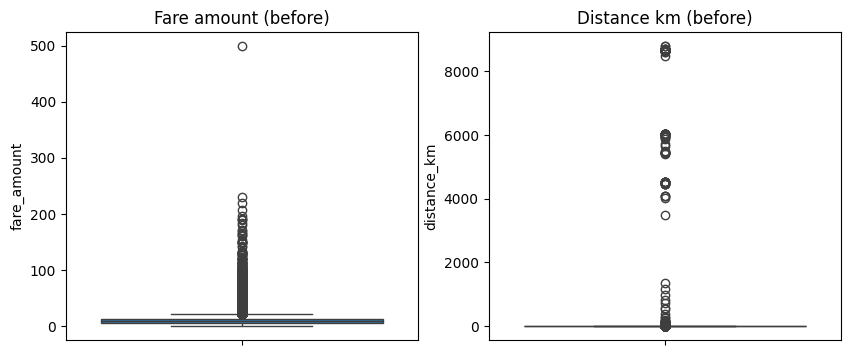

fare_amount: lower=-3.75, upper=22.25, outliers=16619
distance_km: lower=-1.95, upper=6.51, outliers=8006
Shape after outlier removal: (169019, 13)


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=df["fare_amount"], ax=ax[0]); ax[0].set_title("Fare amount (before)")
sns.boxplot(y=df["distance_km"], ax=ax[1]); ax[1].set_title("Distance km (before)")
plt.show()

def remove_outliers_iqr(data, col):
    q1, q3 = data[col].quantile(0.25), data[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((data[col] < lower) | (data[col] > upper)).sum()
    print(f"{col}: lower={lower:.2f}, upper={upper:.2f}, outliers={n_out}")
    return data[(data[col] >= lower) & (data[col] <= upper)]

df = remove_outliers_iqr(df, "fare_amount")
df = remove_outliers_iqr(df, "distance_km")
print("Shape after outlier removal:", df.shape)

### 1.3 Correlation

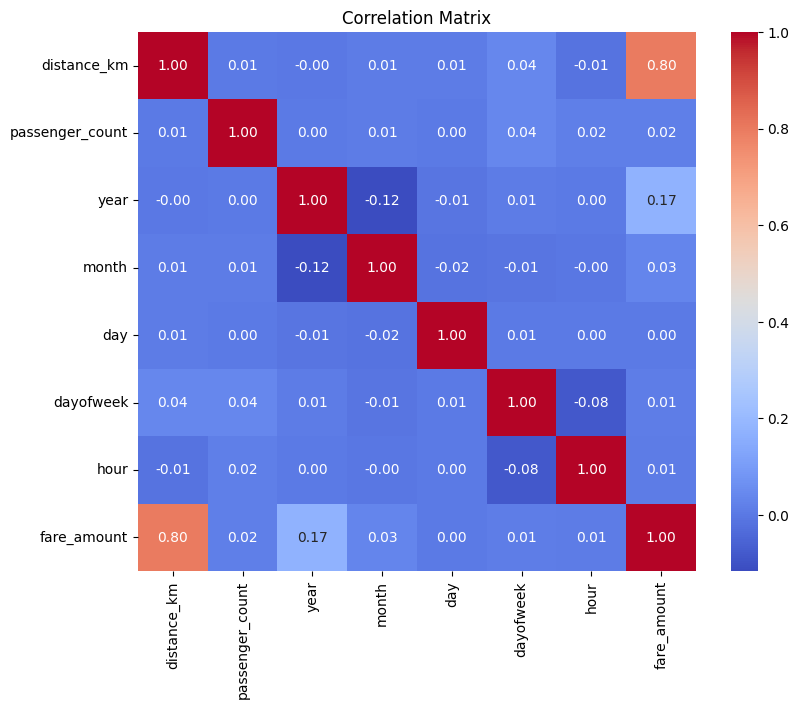

fare_amount        1.000000
distance_km        0.795531
year               0.173208
month              0.032687
passenger_count    0.016702
dayofweek          0.013184
hour               0.006767
day                0.004776
Name: fare_amount, dtype: float64


In [6]:
features = ["distance_km", "passenger_count", "year", "month", "day", "dayofweek", "hour"]
corr = df[features + ["fare_amount"]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()
print(corr["fare_amount"].sort_values(ascending=False))

### 1.4 Build the models

In [7]:
X = df[features]
y = df["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr = LinearRegression().fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
print("Both models trained")

Both models trained
Both models trained


### 1.5 Evaluate and compare

,Model,R2,RMSE,MAE
0,Linear Regression,0.6708,2.1339,1.5250
1,Random Forest Regression,0.7124,1.9946,1.4059


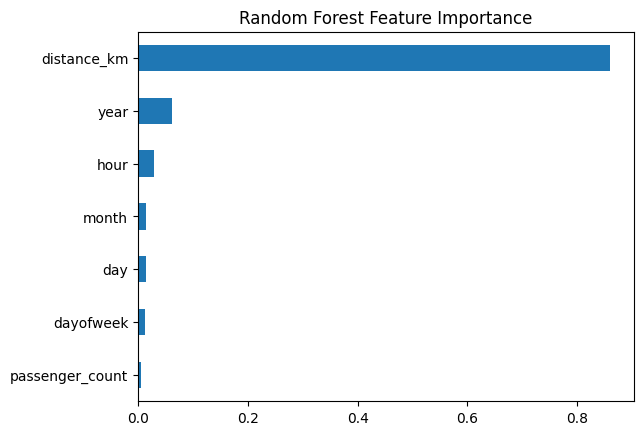

In [8]:
def evaluate(name, model):
    pred = model.predict(X_test)
    return {"Model": name,
            "R2": round(r2_score(y_test, pred), 4),
            "RMSE": round(np.sqrt(mean_squared_error(y_test, pred)), 4),
            "MAE": round(mean_absolute_error(y_test, pred), 4)}

results1 = pd.DataFrame([evaluate("Linear Regression", lr), evaluate("Random Forest Regression", rf)])
display(results1)

pd.Series(rf.feature_importances_, index=features).sort_values().plot(kind="barh")
plt.title("Random Forest Feature Importance"); plt.show()

**Conclusion (Practical 1):** The model with the higher R2 and lower RMSE/MAE in the table above is the better predictor of the fare. Distance is the most important feature.